# Reverse engineering of the linear relational attention head for transitive inference
The purpose of this notebook is to use the insights from our notebook analyzing the linear relational attention head to build our own head from sratch that can perform transitive inference.

## Imports

In [1]:
import numpy as np
import torch
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import seaborn as sns

from relational_attention.tasks import TransitiveInferenceDataset, TransitiveSequenceDataset
from relational_attention.models import RelationalAttentionHead, AttentionClassifier
from relational_attention.training import evaluate_model

In [2]:
torch.manual_seed(42)

## Construct task

In [3]:
# Parameters
num_samples = 1000
num_items = 5

In [4]:
# Testing task
dataset_test = TransitiveInferenceDataset(num_samples=num_samples, num_items=num_items, train=False)
loader_test = DataLoader(dataset_test, batch_size=16, shuffle=True)

In [5]:
dataset_test.data[0], dataset_test.labels[0]

(tensor([[1., 0., 0., 0., 0.],
         [0., 0., 0., 0., 1.]]),
 tensor(1.))

In [6]:
dataset_test.data[2], dataset_test.labels[2]

(tensor([[0., 0., 0., 0., 1.],
         [0., 0., 1., 0., 0.]]),
 tensor(0.))

## Construct weight matrices

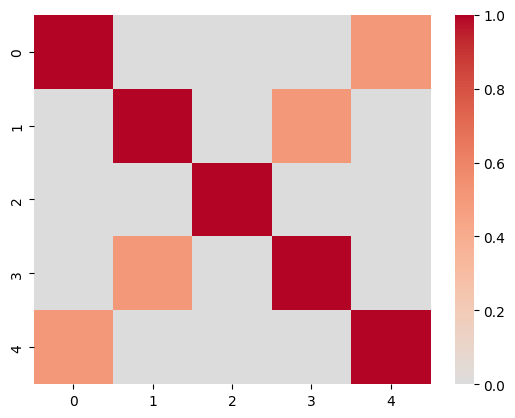

In [7]:
query_mat = np.array([[1.00,    0.00,   0.25,   0.50,   0.75],
                      [0.75,    1.00,   0.00,   0.25,   0.50],
                      [0.50,    0.75,   1.00,   0.00,   0.25],
                      [0.25,    0.50,   0.75,   1.00,   0.00],
                      [0.00,    0.25,   0.50,   0.75,   1.00]])

query_mat = np.array([[1.00,    0.00,   0.00,   0.00,   0.50],
                      [0.00,    1.00,   0.00,   0.50,   0.00],
                      [0.00,    0.00,   1.00,   0.00,   0.00],
                      [0.00,    0.50,   0.00,   1.00,   0.00],
                      [0.50,    0.00,   0.00,   0.00,   1.00]])

sns.heatmap(query_mat, cmap="coolwarm", center=0)
plt.show()

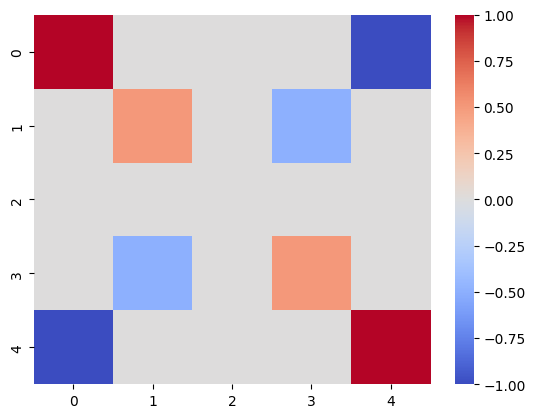

In [8]:
key_mat = np.array([[1,0,0,0,-1],
                      [0,0.5,0,-0.5,0],
                      [0,0,0,0,0],
                      [0,-0.5,0,0.5,0],
                      [-1,0,0,0,1]])
sns.heatmap(key_mat, cmap="coolwarm", center=0)
plt.show()

## Test matrix construction

### Positive example

In [9]:
query_arr = query_mat@(dataset_test.data[0].numpy().T)
query_arr

array([[1. , 0.5],
       [0. , 0. ],
       [0. , 0. ],
       [0. , 0. ],
       [0.5, 1. ]])

In [10]:
key_arr = key_mat@(dataset_test.data[0].numpy().T)
key_arr

array([[ 1., -1.],
       [ 0.,  0.],
       [ 0.,  0.],
       [ 0.,  0.],
       [-1.,  1.]])

In [11]:
query_arr.T@key_arr

array([[ 0.5, -0.5],
       [-0.5,  0.5]])

### Negative example

In [12]:
query_arr = query_mat@(dataset_test.data[2].numpy().T)
query_arr

array([[0.5, 0. ],
       [0. , 0. ],
       [0. , 1. ],
       [0. , 0. ],
       [1. , 0. ]])

In [13]:
key_arr = key_mat@(dataset_test.data[2].numpy().T)
key_arr

array([[-1.,  0.],
       [ 0.,  0.],
       [ 0.,  0.],
       [ 0.,  0.],
       [ 1.,  0.]])

In [14]:
query_arr.T@key_arr

array([[0.5, 0. ],
       [0. , 0. ]])

### Plot for a variety of examples

In [15]:
seq_len = dataset_test.data[0].shape[0]   # should be 2 for paired TI

# Store scores for each attention entry
scores = { (i, j): [] for i in range(seq_len) for j in range(seq_len) }
labels = []

for x, y in zip(dataset_test.data, dataset_test.labels):
    # x: (seq_len, embed_dim)
    x_np = x.numpy().T          # (embed_dim, seq_len)

    # Compute Q and K under your simple matrices
    q = query_mat @ x_np        # (d, seq_len)
    k = key_mat @ x_np          # (d, seq_len)

    # Attention (no softmax): (seq_len, seq_len)
    A = q.T @ k                 # (seq_len, seq_len)

    # Record each entry
    for i in range(seq_len):
        for j in range(seq_len):
            scores[(i, j)].append(A[i, j])

    labels.append(float(y))     # 0.0 or 1.0

labels = np.array(labels)

# Convert scores to numpy arrays
for key in scores:
    scores[key] = np.array(scores[key])

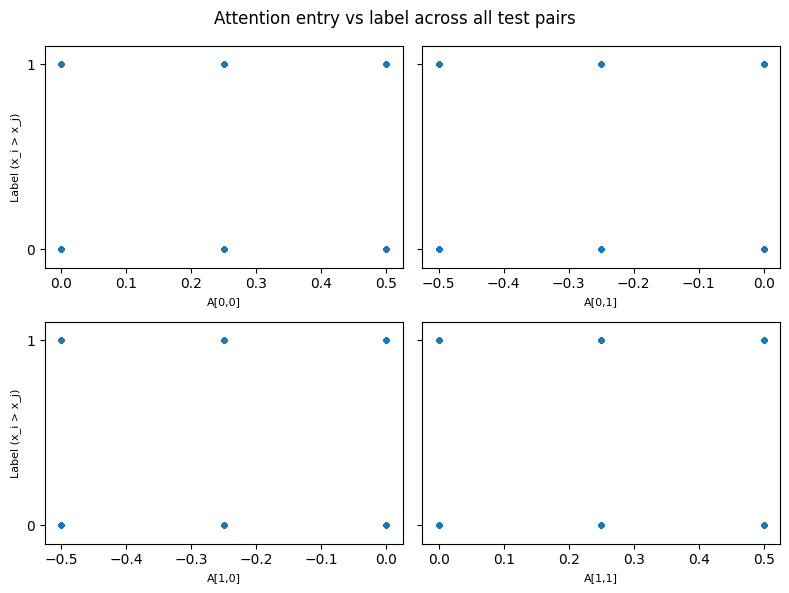

In [16]:
# ---- Plot 4 panels: one per attention entry ----
fig, axes = plt.subplots(seq_len, seq_len, figsize=(8, 6), sharey=True)

for i in range(seq_len):
    for j in range(seq_len):
        ax = axes[i, j] if seq_len > 1 else axes
        s = scores[(i, j)]
        ax.scatter(s, labels, alpha=0.5, s=10)
        ax.set_xlabel(f"A[{i},{j}]", fontsize=8)
        if j == 0:
            ax.set_ylabel("Label (x_i > x_j)", fontsize=8)
        ax.set_ylim(-0.1, 1.1)
        ax.set_yticks([0, 1])

plt.suptitle("Attention entry vs label across all test pairs", fontsize=12)
plt.tight_layout()
plt.show()